In [1]:
# 整理后的R包加载与配置

# 基础分析包
suppressMessages(library(Seurat))
suppressMessages(library(Signac))
suppressMessages(library(dplyr))
suppressMessages(library(ggplot2))
suppressMessages(library(future))
suppressMessages(library(parallel))
# suppressMessages(library(Nebulosa))
suppressMessages(library(RColorBrewer))
suppressMessages(library(viridis))
suppressMessages(library(qs))

# 多组学/转录因子包
suppressMessages(library(scMEGA))
suppressMessages(library(Pando))
suppressMessages(library(harmony))
suppressMessages(library(enrichR))

# motif 分析等
# suppressMessages(library(JASPAR2020))
suppressMessages(library(JASPAR2024))
suppressMessages(library(TFBSTools))
suppressMessages(library(chromVAR))
suppressMessages(library(motifmatchr))

# 可视化
suppressMessages(library(igraph))
suppressMessages(library(ggraph))

# 基因组分析
# suppressMessages(library(BSgenome.Hsapiens.UCSC.hg38))
suppressMessages(library(GenomicRanges))
suppressMessages(library(BSgenome))
suppressMessages(library(Rsamtools))  # FaFile
suppressMessages(library(ChIPseeker))
suppressMessages(library(GenomicFeatures))
suppressMessages(library(rtracklayer)) # 读写 BED/GFF
suppressMessages(library(txdbmaker))
suppressMessages(library(enrichR))
library(tidyr)
library(foreach)
library(doParallel)
library(tidygraph)


# Python 环境
suppressMessages(library(reticulate))
RETICULATE_PYTHON <- "/home/chaiqw/project/betz_snRNA_snATAC/.venv/bin/python"
use_virtualenv("/home/chaiqw/project/betz_snRNA_snATAC/.venv")

# 资源设定
plan("multicore", workers = 64)
options(future.globals.maxSize = 100000 * 1024^5)

# 加载 genome 注释
load('/home/chaiqw/project/macaque_motor_new/macFas5_genomeInfo_signac.RData')
data("motifs");data('motif2tf')
library(pheatmap)
library(dplyr)
library(VennDiagram)

# 网络代理设定
Sys.setenv(
  http_proxy  = "http://10.10.50.114:45698",
  https_proxy = "http://10.10.50.114:45698"
)



载入程序包：‘tidyr’


The following object is masked from ‘package:S4Vectors’:

    expand


The following object is masked from ‘package:igraph’:

    crossing


载入需要的程序包：iterators


载入程序包：‘tidygraph’


The following object is masked from ‘package:AnnotationDbi’:

    select


The following object is masked from ‘package:XVector’:

    slice


The following objects are masked from ‘package:IRanges’:

    active, slice


The following objects are masked from ‘package:S4Vectors’:

    active, rename


The following object is masked from ‘package:igraph’:

    groups


The following object is masked from ‘package:stats’:

    filter


载入需要的程序包：grid


载入程序包：‘grid’


The following object is masked from ‘package:Biostrings’:

    pattern


载入需要的程序包：futile.logger



In [14]:
df = read.csv('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_deg_res-20251205-new-all.csv',row.names = 1)
df

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
POSTN,0.000000e+00,-4.9281742,0.075,0.680,0.000000e+00,POSTN
PTPRK,3.532859e-196,-1.6054102,0.561,0.820,8.233681e-192,PTPRK
CADPS2,3.667570e-118,-1.6493130,0.375,0.644,8.547638e-114,CADPS2
TMEM132D,1.133653e-116,1.4685264,0.699,0.355,2.642091e-112,TMEM132D
PRKD1,1.309835e-114,1.7158324,0.603,0.264,3.052700e-110,PRKD1
FKBP14,4.223241e-110,-2.1844540,0.167,0.471,9.842685e-106,FKBP14
ADAMTSL1,2.192882e-109,-2.0584984,0.203,0.517,5.110731e-105,ADAMTSL1
OPCML,1.041243e-99,0.8366375,0.930,0.833,2.426720e-95,OPCML
TOX,1.328066e-99,1.2132266,0.697,0.377,3.095190e-95,TOX


In [ ]:
deg = df

deg$gene <- rownames(deg)

# 如果 avg_log2FC 大于0，是 snRNA Betz Like Cluster，小于0是 snRNA Other L5_ET-neurons
deg$cluster <- ifelse(deg$avg_log2FC > 0, "snRNA Betz Like Cluster", 
                    ifelse(deg$avg_log2FC < 0, "snRNA Other L5_ET-neurons", NA))


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,gene,cluster
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
POSTN,0.000000e+00,-4.9281742,0.075,0.680,0.000000e+00,POSTN,snRNA Other L5_ET-neurons
PTPRK,3.532859e-196,-1.6054102,0.561,0.820,8.233681e-192,PTPRK,snRNA Other L5_ET-neurons
CADPS2,3.667570e-118,-1.6493130,0.375,0.644,8.547638e-114,CADPS2,snRNA Other L5_ET-neurons
TMEM132D,1.133653e-116,1.4685264,0.699,0.355,2.642091e-112,TMEM132D,snRNA Betz Like Cluster
PRKD1,1.309835e-114,1.7158324,0.603,0.264,3.052700e-110,PRKD1,snRNA Betz Like Cluster
FKBP14,4.223241e-110,-2.1844540,0.167,0.471,9.842685e-106,FKBP14,snRNA Other L5_ET-neurons
ADAMTSL1,2.192882e-109,-2.0584984,0.203,0.517,5.110731e-105,ADAMTSL1,snRNA Other L5_ET-neurons
OPCML,1.041243e-99,0.8366375,0.930,0.833,2.426720e-95,OPCML,snRNA Betz Like Cluster
TOX,1.328066e-99,1.2132266,0.697,0.377,3.095190e-95,TOX,snRNA Betz Like Cluster


In [5]:
write.csv(deg, '/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/Betz_vs_Other_20251205_all.csv')


In [16]:
deg = df

deg$gene <- rownames(deg)

MTGenes <- c("ND6","COX1","ND5","ND4","ND2","ND4L","ATP8","CYTB","COX2","ND3","ATP6","ND1","COX3")
deg_1 <- deg[!deg$gene %in% MTGenes, ]
deg_2 = deg_1 %>% filter(!grepl("^ENSMFAG", gene))


deg_2 = subset(deg_2, p_val_adj < 0.05)
deg_3 = subset(deg_2, avg_log2FC > 0.5|avg_log2FC < -0.5)



In [18]:
# 筛选 avg_log2FC > 0 的基因名
genes_up <- deg_3$gene[deg_3$avg_log2FC > 0]
# 筛选 avg_log2FC < 0 的基因名
genes_down <- deg_3$gene[deg_3$avg_log2FC < 0]
# 只返回基因名的向量
# write.csv(genes_up, "genes_up.csv", row.names = FALSE)
# write.csv(genes_down, "genes_down.csv", row.names = FALSE)

In [19]:
length(genes_up)

[1] 383

In [4]:
sum(deg_3$avg_log2FC > 0)
sum(deg_3$avg_log2FC < 0)

[1] 383

[1] 197

In [2]:
peak_obj = readRDS('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_peak-20251106-new.rds')
peak_obj

An object of class Seurat 
741246 features across 928 samples within 3 assays 
Active assay: peaks (699368 features, 664763 variable features)
 2 layers present: counts, data
 2 other assays present: GeneActivity, RNA
 4 dimensional reductions calculated: pca, umap, harmony, umap_harmony

In [3]:
obj = readRDS('/home/chaiqw/project/betz_anal_new/coembed_5000feature-new05.rds')

sub_rna = subset(obj, tech == 'RNA')
obj_1 = subset(obj, tech == 'ATAC')

obj_1$ET_class <- ifelse(obj_1$seurat_clusters == 2, "Betz Like cluster", "other L5_ET-neuron")

obj_sub = subset(obj_1, obj_1$seurat_clusters == 2)
obj_sub

peaks assay doesn't leave any cells, so it is removed

GeneActivity assay doesn't leave any cells, so it is removed



An object of class Seurat 
730339 features across 325 samples within 3 assays 
Active assay: RNA (10000 features, 10000 variable features)
 2 layers present: data.2, scale.data
 2 other assays present: peaks, GeneActivity
 3 dimensional reductions calculated: pca, harmony, umap

In [4]:
# 按照行名把obj_1中的ET_class添加到peak_obj中
common_cells <- intersect(rownames(peak_obj[[]]), rownames(obj_1[[]]))
peak_obj$ET_class <- NA
peak_obj$ET_class[common_cells] <- obj_1$ET_class[common_cells]

peak_obj

An object of class Seurat 
741246 features across 928 samples within 3 assays 
Active assay: peaks (699368 features, 664763 variable features)
 2 layers present: counts, data
 2 other assays present: GeneActivity, RNA
 4 dimensional reductions calculated: pca, umap, harmony, umap_harmony

In [7]:
### DA peaks Betz Like cluster vs other L5_ET-neuron
df = read.csv('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_peak_da_res-20251223-new-all.csv')
df
# df_sub = subset(df, avg_log2FC > 0.5 & p_val_adj < 0.05)


X,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
chr8-45348359-45351141,7.983791e-20,0.2939891,1.000,0.995,5.583608e-14
chr9-10784448-10785608,1.054873e-19,1.4999312,0.483,0.154,7.377446e-14
chr3-68122333-68123396,1.121110e-19,1.6902161,0.406,0.113,7.840686e-14
chr13-42125046-42126389,4.076558e-18,1.4747106,0.440,0.143,2.851014e-12
chr10-59414799-59416213,6.263626e-18,1.4098406,0.468,0.158,4.380579e-12
chr10-39378331-39380527,1.962226e-17,2.5112830,0.231,0.038,1.372318e-11
chr9-89505358-89506770,2.830828e-17,1.3344611,0.511,0.169,1.979790e-11
chr9-73569374-73570302,4.614453e-17,2.1737129,0.258,0.058,3.227201e-11
chr11-132866605-132867968,8.735986e-17,1.5377365,0.400,0.121,6.109669e-11


In [ ]:
### DEGs
deg_use = read.csv('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_deg_res-20251205-new-subset.csv')

deg_use_sub = subset(deg_use, avg_log2FC > 0.5 & p_val_adj < 0.05)
deg_use_sub

X,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,gene
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
TMEM132D,1.133653e-116,1.4685264,0.699,0.355,2.642091e-112,TMEM132D
PRKD1,1.309835e-114,1.7158324,0.603,0.264,3.052700e-110,PRKD1
OPCML,1.041243e-99,0.8366375,0.930,0.833,2.426720e-95,OPCML
TOX,1.328066e-99,1.2132266,0.697,0.377,3.095190e-95,TOX
ASTN2,1.866135e-96,1.5301002,0.632,0.348,4.349214e-92,ASTN2
LARGE1,5.706472e-87,1.0534169,0.816,0.613,1.329950e-82,LARGE1
KAZN,3.553833e-81,1.0995371,0.814,0.616,8.282563e-77,KAZN
KCNIP1,9.423149e-80,2.4922603,0.300,0.067,2.196159e-75,KCNIP1
NETO1,1.825219e-76,1.4294817,0.517,0.230,4.253856e-72,NETO1


In [12]:
markers_motif_1 = read.csv('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_betz_snRNA/betz_motif_markers.csv')
markers_motif_1_sub = subset(markers_motif_1, cluster == 'Betz Like cluster')
markers_motif_1_sub


,X,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,motif
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
45,MA0501.1,6.115919e-19,5.447498,0.631,0.388,9.724311e-16,Betz Like cluster,MA0501.1
46,MA0089.2,1.434926e-17,5.922768,0.615,0.371,2.281532e-14,Betz Like cluster,MA0089.2
47,MA0490.2,2.137484e-17,15.791188,0.631,0.378,3.398599e-14,Betz Like cluster,MA0490.2
48,MA1101.2,2.283807e-17,12.351772,0.637,0.390,3.631253e-14,Betz Like cluster,MA1101.2
49,MA1142.1,2.664766e-17,13.564488,0.628,0.376,4.236979e-14,Betz Like cluster,MA1142.1
50,MA1135.1,3.616522e-17,13.664825,0.637,0.375,5.750269e-14,Betz Like cluster,MA1135.1
51,MA0477.2,3.811854e-17,17.520690,0.637,0.380,6.060848e-14,Betz Like cluster,MA0477.2
52,MA1132.1,3.896281e-17,15.649587,0.631,0.378,6.195087e-14,Betz Like cluster,MA1132.1
53,M08789-2.00,4.070708e-17,5.270865,0.628,0.362,6.472425e-14,Betz Like cluster,M08789-2.00


In [381]:
subset(motif2tf_use,tf	=='TOX')

subset(motif2tf_use,tf	=='ZBTB16')

motif,tf,origin,gene_id,family,name,symbol,motif_tf
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>
MA0077.1,TOX,SEQ_SIMILARITY,ENSG00000198846,SOX-related factors,SOX9,SOX9,NA


motif,tf,origin,gene_id,family,name,symbol,motif_tf
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>
MA1580.1,ZBTB16,SEQ_SIMILARITY,ENSG00000109906,Other factors with up to three adjacent zinc fingers,ZBTB32,-,NA


In [ ]:
motif2tf_use <- motif2tf %>%
    filter(motif %in% markers_motif_1_sub$motif)

motifs_use <- motifs[unique(motif2tf_use$motif)]

muo_data <- initiate_grn(obj_sub, rna_assay = 'RNA', peak_assay = 'peaks')
muo_data1 <- find_motifs(
    muo_data, 
    genome = BSgenome.Mfascicularis.NCBI.5.0, 
    pfm = motifs_use, 
    motif_tfs = motif2tf_use
)

In [6]:
write.csv(motif2tf_use, "motif2tf_use.csv")

In [79]:
saveRDS(muo_data, 'muo_data.rds')

In [ ]:

putative_target_genes = unique(deg_use_sub$gene)

muo_data2 <- muo_data1 %>% infer_grn(
    genes = putative_target_genes,
    peak_to_gene_method = 'Signac',
    #  upstream = 1e5, downstream = 0,
    only_tss = T, 
    upstream = 250000, downstream = 250000, 
    # method = 'glmnet',
    parallel = T
)

Selecting candidate regulatory regions near genes

Preparing model input

Fitting models for 315 target genes



In [ ]:

muo_data3 <- find_modules(
    muo_data2, 
    min_genes_per_module = 3
)

modules <- NetworkModules(muo_data3) 


Found 69 TF modules



In [ ]:
umap_method = 'weighted'

In [415]:
muo_data3 <- get_network_graph(muo_data3)

Computing gene-gene correlation



Computing weighted regulatory factor

Computing UMAP embedding

Getting network graph



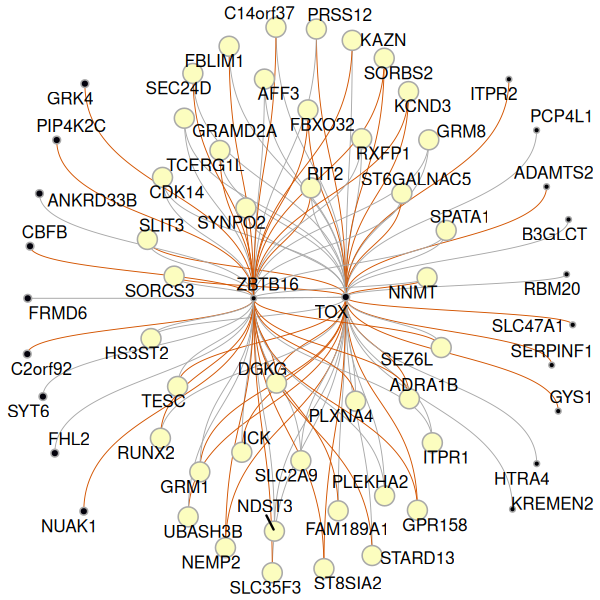

In [418]:
options(repr.plot.width=5, repr.plot.height=5)
plot_network_graph(
    muo_data3,
    # layout='fr',
    layout='stress',
    edge_color = c(`-1` = "darkgrey", `1` = "#d35400"), # 比较深的橙色
    node_color = pals::magma(500)
    
    )

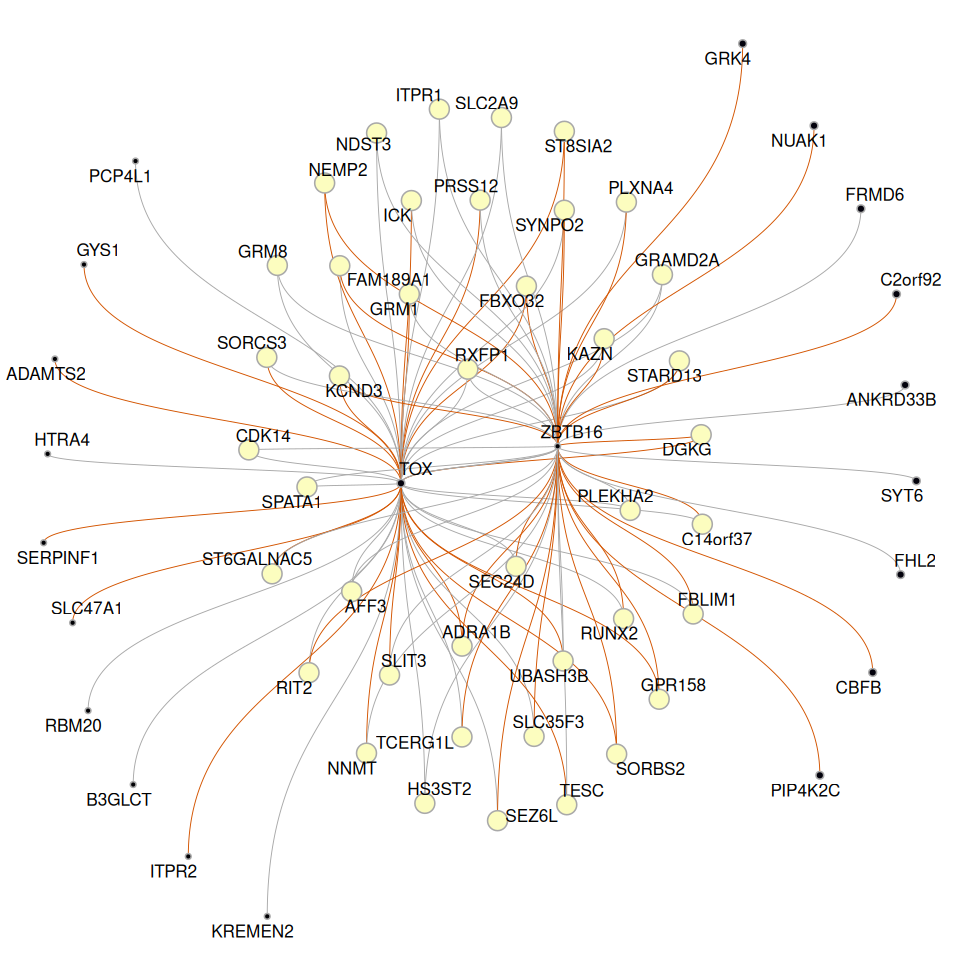

In [406]:
options(repr.plot.width=8, repr.plot.height=8)
plot_network_graph(
    muo_data3_sub2,
    layout='fr',
    # layout='umap',
    edge_color = c(`-1` = "darkgrey", `1` = "#d35400"), # 比较深的橙色
    node_color = pals::magma(500)
    
    )

In [334]:
tf_interest <- c("TOX3", "ZBTB16")


In [ ]:
# 取出前三高 out-degree 的TF及其下游直接靶基因
g <-  muo_data3@grn@networks$glm_network@graphs$module_graph

deg <- degree(g, mode = "out")
top_tf <- names(sort(deg, decreasing = TRUE))[1:50]

# 获取每个top_tf的下游直接邻居
targets_list <- lapply(top_tf, function(tf) {
  neighbors(g, tf, mode = "out")$name
})
names(targets_list) <- top_tf

# 输出结果（每个TF的下游靶基因向量）
targets_list

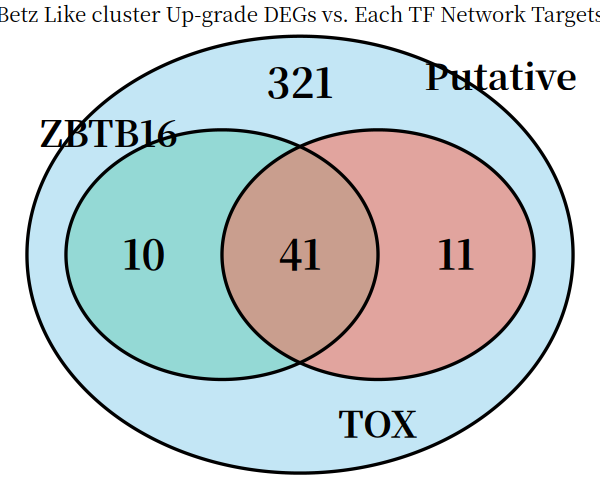

In [ ]:
# 用韦恩图展示 putative_target_genes 和 targets_list 里每个 TF 的下游靶基因的交集情况
options(repr.plot.width=5, repr.plot.height=4)
# targets_list 是一个包含两个TF的list，分别取出两个list的内容
tf1_name <- names(targets_list)[1]
tf2_name <- names(targets_list)[2]
tf1_targets <- unique(targets_list[[1]])
tf2_targets <- unique(targets_list[[2]])

# 构造命名list，避免“:=”和 bang-bang
venn_input <- list(
  Putative = putative_target_genes
)
venn_input[[tf1_name]] <- tf1_targets
venn_input[[tf2_name]] <- tf2_targets

# 画三个集合的韦恩图：putative, TF1, TF2
venn.plot <- venn.diagram(
  x = venn_input,
  filename = NULL,
  fill = c("skyblue", "tomato", "seagreen3"),
  alpha = 0.5,
  cex = 2,
  fontface = "bold",
  cat.cex = 1.8,
  cat.fontface = "bold",
  main = "Betz Like cluster Up-grade DEGs vs. Each TF Network Targets"
)

grid.newpage()
grid.draw(venn.plot)